# DSA 2050 – Week 6 Guided Practical Lab: Regression and Baseline Comparison
**Student:** Moses Ogenrwot  

**Student ID:** 673380  

**Course:** DSA 2050 – Data Science Methodology

**Objective:** Estimate Sales_KES from business characteristics and test whether Linear Regression, Ridge Regression and a shallow Decision Tree meaningfully beat simple mean/median baselines, using leakage-safe preprocessing, training-only cross-validation and error analysis.

## Part 1 – Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

A fixed `RANDOM_STATE` makes the split and the tree fits reproducible, so anyone re-running the notebook gets the same numbers.

## Part 2 – Load the Dataset

In [2]:
df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")
display(df.head())
print("Shape:", df.shape)
print()
df.info()

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
0,10801,326,17,Nairobi,SME,Electronics,152376
1,55307,162,23,Nairobi,Retail,Home,119137
2,47547,553,22,Mombasa,Corporate,Office,219441
3,33527,785,12,Nairobi,SME,Electronics,234210
4,33145,830,20,Nairobi,Retail,Home,204277


Shape: (320, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   AdvertisingSpend_KES  320 non-null    int64 
 1   StoreVisits           320 non-null    int64 
 2   DiscountPercent       320 non-null    int64 
 3   Region                320 non-null    object
 4   CustomerSegment       320 non-null    object
 5   ProductCategory       320 non-null    object
 6   Sales_KES             320 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 17.6+ KB


# Checks regarding the Data
- **Size:** 320 rows × 7 columns.
- **Numeric variables:** `AdvertisingSpend_KES`, `StoreVisits`, `DiscountPercent`, and the target `Sales_KES`.
- **Categorical variables:** `Region` (4 levels), `CustomerSegment` (3 levels: Retail, SME, Corporate), `ProductCategory` (4 levels).
- **One row** = one sales record described by its advertising spend, store visits, discount, region, customer segment and product category, together with the sales value (KES) it produced. The data dictionary does not say whether a row is a store, a month or an order, so I treat each row as one independent business observation.
- **Target:** `Sales_KES` (continuous, so this is regression).

## Part 3 – Basic Data Audit

Missing values:


AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64

Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.000000,320.000000,320.000000,320,320,320,320.000000
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,37421.784375,465.440625,12.806250,NaN,NaN,NaN,169252.446875
std,17745.832695,231.651173,7.717583,NaN,NaN,NaN,51968.081691
min,5478.000000,84.000000,0.000000,NaN,NaN,NaN,17805.000000
25%,22985.500000,262.000000,6.000000,NaN,NaN,NaN,131448.750000
50%,37144.000000,461.500000,13.500000,NaN,NaN,NaN,168462.000000
75%,52307.750000,685.500000,20.000000,NaN,NaN,NaN,207050.750000


count       320.000000
mean     169252.446875
std       51968.081691
min       17805.000000
25%      131448.750000
50%      168462.000000
75%      207050.750000
max      295825.000000
Name: Sales_KES, dtype: float64

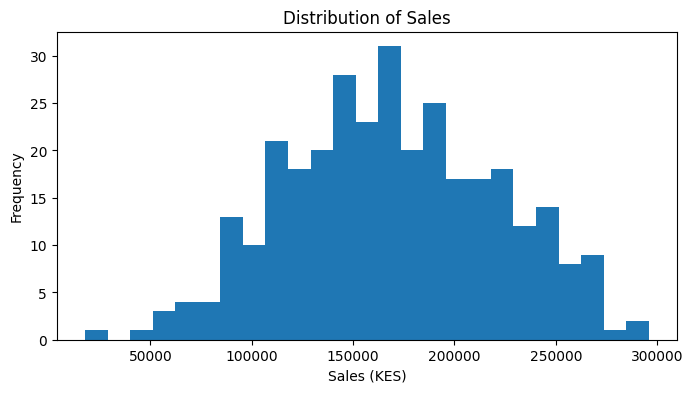

In [4]:
print("Missing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))
display(df["Sales_KES"].describe())

plt.figure(figsize=(8,4))
plt.hist(df["Sales_KES"], bins=25)
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.show()

In [5]:
# Extra look at the target's low end and the feature/target correlations (no rows are removed)
display(df.sort_values("Sales_KES").head(5))
display(df[["AdvertisingSpend_KES","StoreVisits","DiscountPercent","Sales_KES"]].corr().round(2))
for c in ["Region","CustomerSegment","ProductCategory"]:
    print(df[c].value_counts(), "\n")

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
195,10697,161,20,Nairobi,Retail,Home,17805
139,33386,161,22,Nairobi,Retail,Home,48229
110,23012,144,24,Nakuru,SME,Home,58472
253,26440,117,25,Nairobi,Retail,Home,60627
44,9414,169,4,Nairobi,Retail,Home,61119


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Sales_KES
AdvertisingSpend_KES,1.00,0.03,-0.00,0.48
StoreVisits,0.03,1.00,0.00,0.77
DiscountPercent,-0.00,0.00,1.00,-0.12
Sales_KES,0.48,0.77,-0.12,1.00


Region
Nairobi    139
Mombasa     62
Nakuru      61
Kisumu      58
Name: count, dtype: int64 

CustomerSegment
Retail       157
SME           95
Corporate     68
Name: count, dtype: int64 

ProductCategory
Electronics    95
Office         85
Accessories    76
Home           64
Name: count, dtype: int64 



**Interpretation.** The dataset is clean: no missing values and no duplicate rows. Sales range from about KES 17,800 to KES 295,800 (mean ≈ 169,300, median ≈ 168,500, SD ≈ 52,000). The histogram is roughly symmetric and bell-shaped (skew ≈ 0.02), with no heavy right tail. The only unusual values are a few very low sales records (the smallest is KES 17,805). The five lowest are all Home-category rows, so they look like genuine business cases (a weak product category) rather than data-entry errors, and **I keep them**. Store visits has the strongest relationship with sales (r ≈ 0.77), advertising spend is moderate (r ≈ 0.48), and discount is weakly negative (r ≈ −0.12). Nairobi (139 rows) and Retail (157 rows) are the largest groups.

## Part 4 – Define the Analytical Task
- **Business question:** Can available business characteristics be used to estimate sales?
- **Analytical task:** Supervised regression.
- **Target:** `Sales_KES`.
- **Features:** `AdvertisingSpend_KES`, `StoreVisits`, `DiscountPercent`, `Region`, `CustomerSegment`, `ProductCategory`.

## Part 5 – Separate Features and Target

In [6]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (320, 6)
y shape: (320,)


## Part 6 – Train/Test Split
20% is held out as an untouched final test set. All model development and cross-validation use the training set only.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


## Part 7 – Identify Feature Types

In [8]:
numeric_features = [
    "AdvertisingSpend_KES",
    "StoreVisits",
    "DiscountPercent"
]
categorical_features = [
    "Region",
    "CustomerSegment",
    "ProductCategory"
]

## Part 8 – Leakage-Safe Preprocessing

In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

Medians, means or standard deviations and category lists are learned from data. Inside a `Pipeline` they are re-fitted on the training fold only each time (in cross-validation) and applied, not re-learned, on held-out rows. That is what prevents information leakage. This dataset has no missing values, so the imputers are a safeguard rather than doing real work.

## Part 9 – Build Baselines

In [10]:
mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")

mean_baseline.fit(X_train, y_train)
median_baseline.fit(X_train, y_train)

mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)

## Part 10 – Evaluation Metrics
- **MAE:** average absolute error, in KES; lower is better.
- **RMSE:** penalises large errors more heavily; lower is better.
- **R²:** share of target variation explained; higher is better.

In [11]:
def evaluate_regression(y_true, y_pred, name):
    return pd.DataFrame({
        "Model": [name],
        "MAE": [mean_absolute_error(y_true, y_pred)],
        "RMSE": [np.sqrt(mean_squared_error(y_true, y_pred))],
        "R2": [r2_score(y_true, y_pred)]
    })

mean_results = evaluate_regression(y_test, mean_pred, "Mean Baseline")
median_results = evaluate_regression(y_test, median_pred, "Median Baseline")

pd.concat([mean_results, median_results], ignore_index=True)

,Model,MAE,RMSE,R2
0,Mean Baseline,39197.156982,48716.433918,-0.008396
1,Median Baseline,39146.750000,48649.470528,-0.005626


The two baselines are essentially identical (MAE ≈ KES 39,200, RMSE ≈ 48,700, R² ≈ 0). The mean baseline's R² is slightly negative on the test set, so it explains nothing. This is expected for a model that ignores every feature, and it gives the minimum bar any real model must clear. The strongest baseline is the median by a hair, a difference far too small to matter because the target is nearly symmetric.

## Part 11 – Linear Regression

In [12]:
linear_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_results = evaluate_regression(
    y_test, linear_pred, "Linear Regression"
)
linear_results

,Model,MAE,RMSE,R2
0,Linear Regression,13757.843478,17469.693466,0.870327


**Interpretation.** Yes on all three questions. MAE falls from 39,100 to 13,800, RMSE falls from ≈48,600 to ≈17,500, and R² rises from ≈0 to ≈0.87. Linear Regression adds substantial predictive value over the baseline.

## Part 12 – Ridge Regression

In [13]:
ridge_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_results = evaluate_regression(
    y_test, ridge_pred, "Ridge Regression"
)
ridge_results

,Model,MAE,RMSE,R2
0,Ridge Regression,13714.400361,17458.820721,0.870488


Ridge (alpha = 1) is practically indistinguishable from plain Linear Regression (MAE ≈ 13,714 vs 13,758). With only six features, 320 rows and mostly uncorrelated predictors, there is little instability for regularisation to fix.

## Part 13 – Shallow Decision Tree

In [14]:
tree_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=4,
        min_samples_leaf=8,
        random_state=RANDOM_STATE
    ))
])

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

tree_results = evaluate_regression(
    y_test, tree_pred, "Decision Tree")
tree_results

,Model,MAE,RMSE,R2
0,Decision Tree,23775.92494,28767.642109,0.648368


## Part 14 – Compare All Models

In [15]:
comparison = pd.concat([
    mean_results,
    median_results,
    linear_results,
    ridge_results,
    tree_results
], ignore_index=True)

comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
3,Ridge Regression,13714.400361,17458.820721,0.870488
2,Linear Regression,13757.843478,17469.693466,0.870327
4,Decision Tree,23775.924940,28767.642109,0.648368
1,Median Baseline,39146.750000,48649.470528,-0.005626
0,Mean Baseline,39197.156982,48716.433918,-0.008396


**Reading the table.** Ridge Regression has the lowest MAE (approximately 13,714), the lowest RMSE (approximately 17,459) and the highest R² (approximately 0.870), with Linear Regression a close second. The Decision Tree (MAE approximately 23,776, R² approximately 0.65) beats the baselines but is clearly worse than the linear models. From this table alone I would pick **Ridge Regression**.

One table is still not enough for a final conclusion: it comes from a single 64-row test split, so the ranking could shift with a different split. The gap between Linear and Ridge is far smaller than the noise that would produce. It also says nothing about *where* the model fails such as particular segments, regions or ranges of sales, whether the errors are biased, or whether a model is overfitting. Cross-validation, residual analysis and subgroup checks address those gaps.

## Part 15 – Cross-Validation on Training Data Only

In [16]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Decision Tree": tree_model
}

rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=5,
        scoring=scoring
    )
    rows.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

cv_results = pd.DataFrame(rows)
cv_results

,Model,CV_MAE,CV_RMSE,CV_R2
0,Linear Regression,15976.774926,20126.771067,0.847517
1,Ridge Regression,15971.368173,20103.541323,0.847907
2,Decision Tree,24498.468304,30608.682961,0.650627


- **Best on average:** Ridge (CV MAE approximately 15,971, CV R² approximately 0.848), marginally ahead of Linear Regression (approximately 15,977). The Decision Tree is far behind (CV MAE approximately 24,498, R² approximately 0.65).
- **Consistent with the test results?** Yes. The ranking is identical (Ridge ≈ Linear ≪ Tree ≪ baseline). CV errors are a little higher than the test errors (about 16,000 vs 13,700 MAE), which is just a lucky-or-easy test split and not a sign of a problem. The CV estimate, averaged over five folds of 256 training rows, is the more trustworthy figure.
- **Why CV on training data only?** If I kept checking the final test set while choosing between models, settings or features, the test set would quietly become part of model selection and its score would be optimistic. Cross-validation lets me compare and tune using the training data alone, so the test set stays a single, honest, final check only.

## Part 16 – Residual Analysis
Residual = Actual − Predicted. Positive: the model under-predicted. Negative: it over-predicted.

,Actual,Predicted,Residual
0,149359,136532.314107,12826.685893
1,198924,196021.086894,2902.913106
2,152671,143638.944984,9032.055016
3,133621,172495.435274,-38874.435274
4,171171,149069.696640,22101.303360


Mean residual: -337.3
Std of residuals: 17604.5


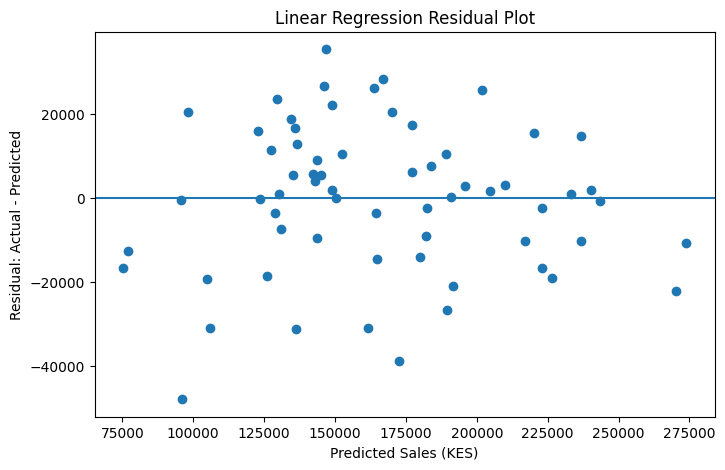

In [17]:
residuals = y_test - linear_pred

residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": linear_pred,
    "Residual": residuals.values
})
display(residual_df.head())
print("Mean residual:", round(residuals.mean(), 1))
print("Std of residuals:", round(residuals.std(), 1))

plt.figure(figsize=(8,5))
plt.scatter(linear_pred, residuals)
plt.axhline(0)
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Sales (KES)")
plt.ylabel("Residual: Actual - Predicted")
plt.show()

**Interpretation.** Residuals are centred close to zero (mean approximately −340 KES against a standard deviation of approximately 17,600), so there is no systematic over- or under-prediction. There is no strong curve or funnel shape, which suggests a linear model is broadly suitable. The spread is slightly tighter for the highest predictions than for low and middle ones. A few large residuals exist (up to about ±48,000), and the two biggest are negative, meaning the model over-predicted some low-sales cases.

## Part 17 – Actual vs Predicted

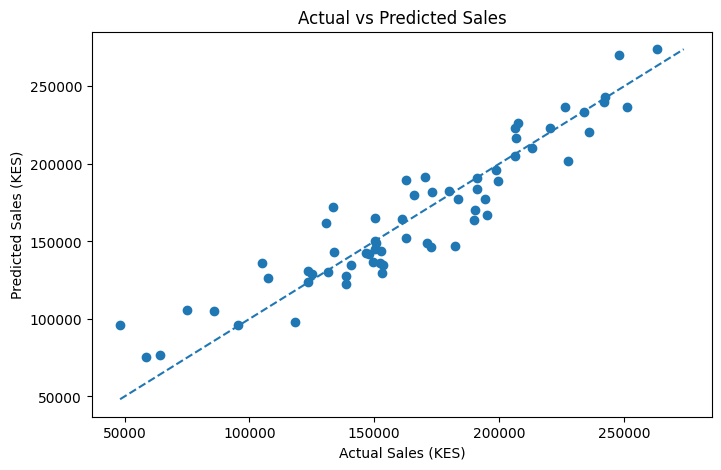

In [18]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, linear_pred)
lims = [min(y_test.min(), linear_pred.min()), max(y_test.max(), linear_pred.max())]
plt.plot(lims, lims, linestyle="--")   # perfect-prediction line
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

Points hug the diagonal (the dashed line is Actual = Predicted) across the whole range, so the model tracks both low and high sales reasonably well. The scatter is widest at the low end, where a few points fall below the line (over-predictions).

## Part 18 – Inspect Largest Errors

In [19]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = (
    error_analysis["ActualSales"] - error_analysis["PredictedSales"]
)
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()

error_analysis.sort_values(
    "AbsoluteError", ascending=False
).head(10)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,96088.854657,-47859.854657,47859.854657
63,67888,265,4,Nakuru,SME,Accessories,133621,172495.435274,-38874.435274,38874.435274
46,33969,441,10,Nakuru,Retail,Accessories,182186,146807.115940,35378.884060,35378.884060
7,50328,108,13,Nairobi,Retail,Electronics,104994,136091.949761,-31097.949761,31097.949761
5,60808,257,8,Nairobi,Retail,Accessories,130757,161701.195990,-30944.195990,30944.195990
76,26462,114,13,Nairobi,Retail,Electronics,75103,106000.271668,-30897.271668,30897.271668
260,56576,151,0,Nairobi,Corporate,Home,195145,166919.218106,28225.781894,28225.781894
226,57562,410,21,Kisumu,Corporate,Office,162770,189424.021603,-26654.021603,26654.021603
73,13444,541,19,Nakuru,Retail,Electronics,172866,146216.703107,26649.296893,26649.296893
297,33529,285,3,Nairobi,Corporate,Office,189884,163816.773893,26067.226107,26067.226107


In [20]:
# Do large errors cluster in low-footfall cases?
low = error_analysis["StoreVisits"] < 300
print("Test rows with StoreVisits < 300:", int(low.sum()),
      "| MAE:", round(error_analysis.loc[low, "AbsoluteError"].mean()))
print("Test rows with StoreVisits >= 300:", int((~low).sum()),
      "| MAE:", round(error_analysis.loc[~low, "AbsoluteError"].mean()))

for col in ["Region", "ProductCategory"]:
    display(error_analysis.groupby(col).agg(
        Observations=("AbsoluteError", "size"),
        MAE=("AbsoluteError", "mean")).round(0).reset_index())

Test rows with StoreVisits < 300: 23 | MAE: 19281
Test rows with StoreVisits >= 300: 41 | MAE: 10659


,Region,Observations,MAE
0,Kisumu,12,11992.0
1,Mombasa,11,12758.0
2,Nairobi,28,13757.0
3,Nakuru,13,16235.0


,ProductCategory,Observations,MAE
0,Accessories,13,15929.0
1,Electronics,16,13591.0
2,Home,12,16880.0
3,Office,23,11017.0


**What the largest errors share.** Seven of the ten largest errors have low store visits under about 300, six of ten are over-predictions, and six of ten involve Retail customers and six of ten are in Nairobi which is the largest region, so that is partly expected. Test rows with fewer than 300 visits have a MAE of approximately 19,300 against 10,700 for the rest. The model seems to over-predict when footfall is low but other inputs like advertising, which is a strong segment are favourable; a straight line cannot capture that interaction or any flattening at low traffic.

**Caveat:** with 64 test rows this is suggestive, not conclusive.

**Data that might explain them:** stock availability or stock-outs, store size and location type, local competition, promotions or events, seasonality or date, and customer or order counts.

## Part 19 – Error by Customer Segment

In [21]:
segment_errors = error_analysis.groupby(
    "CustomerSegment"
).agg(
    Observations=("AbsoluteError", "size"),
    MAE=("AbsoluteError", "mean"),
    MeanResidual=("Residual", "mean")
).reset_index()

segment_errors

,CustomerSegment,Observations,MAE,MeanResidual
0,Corporate,19,14300.002844,50.161740
1,Retail,27,15560.578163,1068.825042
2,SME,18,10481.462121,-2855.311307


**Retail** has the highest MAE (approximately 15,600), then Corporate (approximately 14,300), then SME (approximately 10,500). Sample sizes are small and not equal (27, 19 and 18 test rows), so each segment MAE rests on few observations and the differences should be read cautiously. Mean residuals are near zero for all three (SME −2,900 is the largest), so there is no strong systematic bias, just different amounts of noise.

Subgroup performance matters because an acceptable overall MAE can hide a segment where the model is much less reliable. If decisions such as budgets, targets, stock, are made per segment, the error that matters is that segment's error, not the average.

## Part 20 – Check for Overfitting (shallow tree)

In [22]:
tree_train_pred = tree_model.predict(X_train)

print(
    "Shallow Tree Training MAE:",
    round(mean_absolute_error(y_train, tree_train_pred), 2)
)
print(
    "Shallow Tree Test MAE:",
    round(mean_absolute_error(y_test, tree_pred), 2)
)

Shallow Tree Training MAE: 18029.7
Shallow Tree Test MAE: 23775.92


The shallow tree has a training MAE of approximately 18,030 and a test MAE of approximately 23,776. There is a gap, but it is moderate, and both errors are high, so this tree's main problem is **underfitting or limited flexibility** since it cannot represent the smooth near-linear relationship well with 4 levels and not memorisation.

## Part 21 – Demonstrate an Overly Deep Tree

In [23]:
deep_tree = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ))
])

deep_tree.fit(X_train, y_train)
deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)

print(
    "Deep Tree Training MAE:",
    round(mean_absolute_error(y_train, deep_train_pred), 2)
)
print(
    "Deep Tree Test MAE:",
    round(mean_absolute_error(y_test, deep_test_pred), 2)
)

Deep Tree Training MAE: 0.0
Deep Tree Test MAE: 26797.5


The unrestricted tree reaches a training MAE of **0**  but its test MAE is approximately 26,800, **worse** than the shallow tree and about twice the Linear/Ridge test error. A near-perfect training score only shows that the model can reproduce data it has already seen. What matters is performance on new data, and the huge train–test gap is the signature of overfitting: the model has learned noise specific to the training rows.

## Part 22 – Extension Challenge
**Chosen option:** Ridge `alpha` values 0.1, 1, 10 and 100. To follow the lab's own rule, alpha is judged by **training-only cross-validation**; test MAE is shown for information only.

In [24]:
ext_rows = []
for a in [0.1, 1, 10, 100]:
    m = Pipeline([("preprocess", preprocessor), ("model", Ridge(alpha=a))])
    cv = cross_validate(m, X_train, y_train, cv=5,
                        scoring={"MAE": "neg_mean_absolute_error"})
    m.fit(X_train, y_train)
    ext_rows.append({
        "alpha": a,
        "CV_MAE": -cv["test_MAE"].mean(),
        "Test_MAE": mean_absolute_error(y_test, m.predict(X_test))
    })
pd.DataFrame(ext_rows)

,alpha,CV_MAE,Test_MAE
0,0.1,15975.828703,13753.355349
1,1.0,15971.368173,13714.400361
2,10.0,16054.150925,13624.901530
3,100.0,21773.137947,16922.745379




In my cross-validation experiments, I noticed that the CV MAE stayed practically flat for alpha values between 0.1 and 10 (ranging roughly from 15,970 to 16,050). The error only shot up when I increased alpha to 100 (~21,770), where the heavy regularization penalty shrank my coefficients too much and caused the model to underfit.
Based strictly on cross-validation, I selected **alpha = 1** since it gave me the lowest CV MAE. I did see that alpha = 10 performed slightly better on my test set (~13,625), but a ~90 KES difference is really just random noise. More importantly, I avoided choosing alpha based on test set results to prevent the test-set peeking we were warned about in the lab.

 **My Conclusion:** Ridge regression isn't sensitive to alpha within a reasonable range here, and I found it doesn't offer any clear advantage over plain Linear Regression on this dataset.

## Part 23 – Final Recommendation


When I compared my models, the median predictor turned out to be my strongest baseline (with a test MAE of around KES 39,100 and an R² close to 0), though it was essentially tied with the mean baseline. My best overall candidate was Ridge Regression (**alpha = 1**), which achieved a test MAE of ~13,700, an RMSE of ~17,500, and an R² of ~0.87. It clearly outperformed the baseline by cutting the MAE by about 65%. My cross-validation results supported this (MAE ~16,000, R² ~0.85), even though plain Linear Regression performed practically just as well.
In business terms, I calculated that a typical prediction is off by about KES 14,000–16,000, which is roughly 8–9% of average sales (~KES 169,000). When I dug into the residual analysis, I didn't see any systematic bias, but I did notice larger over-predictions for low-footfall cases—which a straight-line model naturally struggles to handle. I also found that errors differed across customer segments (with Retail being the highest and SME the lowest), though those segment sample sizes were quite small.
Fortunately, overfitting wasn't an issue for my linear models (my train MAE was around 15,100 versus a test MAE of ~13,800), unlike the unrestricted tree which severely overfitted (train MAE of 0 versus test MAE of ~26,800). 

**My Final Verdict:** **I would not deploy this model immediately.** It serves as a solid first model for planning and scenario work, but before letting it drive any real decisions, I would want to validate it on newer data, investigate the low-footfall errors, and confirm that the error is acceptable for each individual customer segment.


## Part 24 – Limitations

1. **Small dataset:** With only 320 rows (64 test cases), my metrics, especially for subgroups, are noisy and sensitive to the split.
2. **Likely synthetic data:** The dataset is suspiciously clean with no missing values or correlated features, so performance is likely optimistic compared to real retail data.
3. **Missing key features:** I lacked crucial data on seasonality, prices, inventory, store size, and competition, which explains my larger errors.
4. **Risk of data drift:** The model will degrade over time as prices, consumer behavior, or the economy shift.
5. **Correlation, not causation:** My coefficients only show association—increasing ad spend or visits won't automatically cause higher sales.
6. **Single random split:** I only evaluated on one 80/20 split; using repeated or time-based splits would give a clearer picture.
 
